# Búsquedas de 4 películas y un meme (Google Trends)

**Pregunta:** ¿cuánto se buscó cada tema por día, y cuáles subieron y bajaron juntos?

**Temas:** *A Minecraft Movie*, *Chicken Jockey*, *Lilo & Stitch* y *Cómo entrenar a tu dragón*.

**Por qué se pueden comparar:** los cuatro temas salen de una sola descarga, así que sus números están en la misma escala (de 0 a 100). Igual que antes, el 100 es el día con más búsquedas de cada tema dentro de esa descarga. No sirve para comparar con otra descarga hecha en otra fecha.

**Período del archivo:** el archivo tiene datos del 1 de enero al 30 de junio de **2026**. El rango que usamos está en la primera parte del notebook.

## 1. Preparación

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Donde esta el archivo
RUTA = "../data/raw/tendencias_4_peliculas_2025-01-01_2025-06-30.csv"

# Periodo que vamos a mirar (ano-mes-dia)
# El archivo actual tiene fechas de 2026. Si cambias por un archivo de 2025, cambia estas fechas.
INICIO = "2026-01-01"
FIN = "2026-06-30"

## 2. Abrir el archivo

In [2]:
# Las dos primeras lineas del archivo no son datos, por eso las salteamos
raw = pd.read_csv(RUTA, skiprows=2)
print("Filas en el archivo:", len(raw))
raw.head()

Filas en el archivo: 181


,Día,Una película de Minecraft: (Todo el mundo),Chicken Jockey: (Todo el mundo),Lilo & Stitch: (Todo el mundo),Cómo entrenar a tu dragón: (Todo el mundo)
0,2026-01-01,50,3,27,71
1,2026-01-02,43,3,21,72
2,2026-01-03,38,3,23,80
3,2026-01-04,37,2,22,84
4,2026-01-05,28,2,16,52


In [3]:
# Ordenar la tabla con nombres cortos y el dia como titulo de cada fila
df = pd.DataFrame(
    {
        "Minecraft": raw.iloc[:, 1].values,
        "Chicken Jockey": raw.iloc[:, 2].values,
        "Lilo & Stitch": raw.iloc[:, 3].values,
        "Cómo entrenar a tu dragón": raw.iloc[:, 4].values,
    },
    index=raw["Día"].values,
)

# Quedarnos solo con el periodo elegido
df = df[(df.index >= INICIO) & (df.index <= FIN)]

print("Datos vacíos:", df.isnull().sum().sum())
print(f"Días que vamos a mirar: {len(df)}")
print(f"Desde {df.index[0]} hasta {df.index[-1]}")
df.head()

Datos vacíos: 0
Días que vamos a mirar: 181
Desde 2026-01-01 hasta 2026-06-30


,Minecraft,Chicken Jockey,Lilo & Stitch,Cómo entrenar a tu dragón
2026-01-01,50,3,27,71
2026-01-02,43,3,21,72
2026-01-03,38,3,23,80
2026-01-04,37,2,22,84
2026-01-05,28,2,16,52


## 3. Números generales

In [4]:
df.describe().round(1)

,Minecraft,Chicken Jockey,Lilo & Stitch,Cómo entrenar a tu dragón
count,181.0,181.0,181.0,181.0
mean,21.6,2.6,15.3,33.4
std,6.4,0.6,5.3,15.5
min,14.0,1.0,11.0,16.0
25%,17.0,2.0,13.0,22.0
50%,20.0,3.0,14.0,29.0
75%,24.0,3.0,16.0,39.0
max,50.0,4.0,60.0,100.0


## 4. Gráfico de los cuatro temas

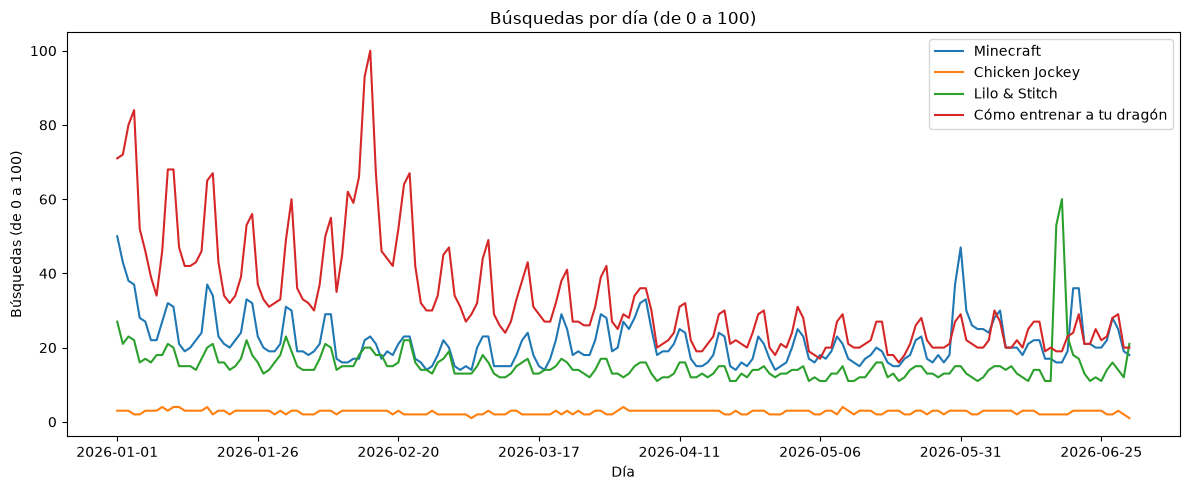

In [5]:
ax = df.plot(figsize=(12, 5), title="Búsquedas por día (de 0 a 100)")
ax.set_xlabel("Día")
ax.set_ylabel("Búsquedas (de 0 a 100)")
plt.tight_layout()
plt.show()

## 5. Punto más alto de cada tema

In [6]:
for tema in df.columns:
    punto_mas_alto = df[tema].max()
    dia = df[df[tema] == punto_mas_alto].index[0]
    print(f"{tema}: su punto más alto fue {punto_mas_alto} el día {dia}")

Minecraft: su punto más alto fue 50 el día 2026-01-01
Chicken Jockey: su punto más alto fue 4 el día 2026-01-09
Lilo & Stitch: su punto más alto fue 60 el día 2026-06-18
Cómo entrenar a tu dragón: su punto más alto fue 100 el día 2026-02-15


## 6. Promedio de cada tema

In [7]:
promedio = df.mean().round(1)
print("Promedio diario de cada tema:")
print(promedio)

Promedio diario de cada tema:
Minecraft                    21.6
Chicken Jockey                2.6
Lilo & Stitch                15.3
Cómo entrenar a tu dragón    33.4
dtype: float64


In [8]:
# Cuantas veces mas (o menos) se busca cada tema, comparado con Minecraft
print("Comparado con Minecraft (1 = igual):")
for tema in df.columns:
    print(f"{tema}: {promedio[tema] / promedio['Minecraft']:.2f}")

Comparado con Minecraft (1 = igual):
Minecraft: 1.00
Chicken Jockey: 0.12
Lilo & Stitch: 0.71
Cómo entrenar a tu dragón: 1.55


## 7. ¿Qué temas suben y bajan juntos?

In [9]:
# Cerca de 1: suben y bajan casi igual.
# Cerca de 0: no tienen nada que ver entre si.
df.corr().round(2)

,Minecraft,Chicken Jockey,Lilo & Stitch,Cómo entrenar a tu dragón
Minecraft,1.00,0.30,0.28,0.50
Chicken Jockey,0.30,1.00,-0.06,0.18
Lilo & Stitch,0.28,-0.06,1.00,0.36
Cómo entrenar a tu dragón,0.50,0.18,0.36,1.00


Un número cerca de 1 quiere decir que dos temas suben y bajan casi igual. Un número cerca de 0 quiere decir que no tienen nada que ver. Este análisis mira días, pero no dice por qué pasa cada cosa.

## 8. Qué podemos decir

**Lo que muestran los datos del archivo (enero a junio de 2026):**

- *Cómo entrenar a tu dragón* es el tema que más se busca. Su promedio diario es unas 1,5 veces el de *A Minecraft Movie*.
- *Chicken Jockey* casi no se busca. Su promedio es muy bajo y nunca supera 4.
- *Lilo & Stitch* tiene un pico muy grande un día de junio. Fuera de ese día, se busca menos que *Cómo entrenar a tu dragón*.
- *A Minecraft Movie* y *Cómo entrenar a tu dragón* son los dos temas que más se parecen en cómo suben y bajan.

**Lo que no podemos decir:**

- Por qué pasó cada pico. Los datos muestran cuándo, pero no el motivo.
- Cómo se compara esto con 2025. Para eso hace falta el archivo del primer semestre de 2025.